# 02 · Exploratory analysis & stationarity
Questions:
1. How strong is the seasonal cycle (winter smog vs monsoon clearing)?
2. How does PM2.5 move with NO₂, SO₂, humidity and wind?
3. Which transformations make the series stationary (needed for VAR/Granger and to pick SARIMAX d, D)?

In [1]:
import sys
sys.path.append("..")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from src.data import PROCESSED, RESULTS, SEASONS, OTHER_SEASON
from src.aqi import pm25_category, CATEGORIES
from src.tsa import stationarity_table
from src.plots import (use_style, savefig, shade_aqi_bands, SEASON_COLORS, LABELS,
                       BLUE, ORANGE, AQUA, NEUTRAL, INK, INK_2, MUTED, SURFACE)

use_style()
daily = pd.read_csv(PROCESSED / "delhi_daily.csv", index_col="Date", parse_dates=True).asfreq("D")
weekly = pd.read_csv(PROCESSED / "delhi_weekly.csv", index_col="Date", parse_dates=True)
key = {}  # headline numbers for the slides

## 1. PM2.5 over time, against CPCB AQI bands

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


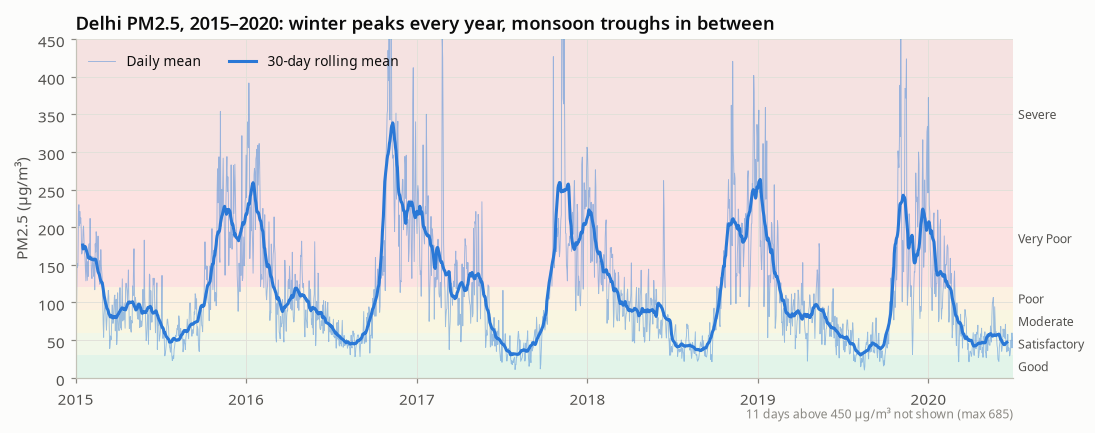

In [2]:
fig, ax = plt.subplots(figsize=(11, 4))
ymax = 450
shade_aqi_bands(ax, ymax)
ax.plot(daily.index, daily["pm25"], color=BLUE, lw=0.6, alpha=0.45, label="Daily mean")
ax.plot(daily.index, daily["pm25"].rolling(30, center=True).mean(), color=BLUE, lw=2, label="30-day rolling mean")
ax.set_ylim(0, ymax)
ax.set_xlim(daily.index.min(), daily.index.max())
ax.set_ylabel(LABELS["pm25"])
ax.set_title("Delhi PM2.5, 2015–2020: winter peaks every year, monsoon troughs in between")
ax.legend(loc="upper left", ncols=2)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
clipped = (daily["pm25"] > ymax).sum()
ax.annotate(f"{clipped} days above {ymax} µg/m³ not shown (max {daily['pm25'].max():.0f})",
            xy=(1, -0.12), xycoords="axes fraction", ha="right", fontsize=8, color=MUTED)
savefig(fig, "01_pm25_timeseries")
plt.show()

In [3]:
cat_share = pm25_category(daily["pm25"].to_numpy()).value_counts(normalize=True).reindex(CATEGORIES) * 100
key["pct_days_poor_or_worse"] = round(float(cat_share[["Poor", "Very Poor", "Severe"]].sum()), 1)
cat_share.round(1).rename("% of days").to_frame()

,% of days
Good,5.0
Satisfactory,22.5
Moderate,20.3
Poor,14.7
Very Poor,30.2
Severe,7.3


## 2. Seasonality: month-by-month distribution (headline figure)

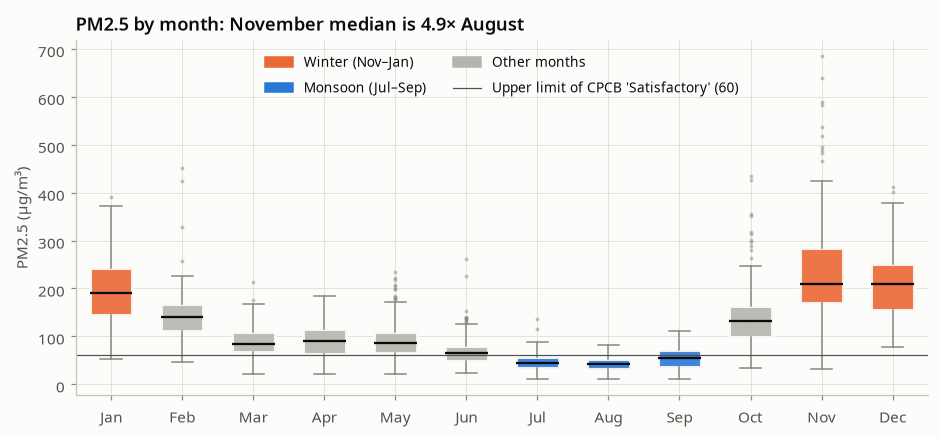

In [4]:
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
by_month = [daily.loc[daily.index.month == m, "pm25"].dropna() for m in range(1, 13)]
month_season = {m: name for name, months in SEASONS.items() for m in months}
colours = [SEASON_COLORS[month_season.get(m, OTHER_SEASON)] for m in range(1, 13)]

monthly_median = daily["pm25"].groupby(daily.index.month).median()
key_ratio = monthly_median[11] / monthly_median[8]

fig, ax = plt.subplots(figsize=(10, 4.2))
bp = ax.boxplot(by_month, tick_labels=month_names, patch_artist=True, widths=0.6,
                showfliers=True, medianprops=dict(color=INK, lw=1.5),
                whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED),
                flierprops=dict(marker="o", markersize=2.5, markerfacecolor=MUTED, markeredgecolor="none", alpha=0.5))
for box, c in zip(bp["boxes"], colours):
    box.set(facecolor=c, edgecolor=SURFACE, linewidth=2, alpha=0.9)
ax.set_ylabel(LABELS["pm25"])
ax.set_title(f"PM2.5 by month: November median is {key_ratio:.1f}× August")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in SEASON_COLORS.values()]
limit = ax.axhline(60, color=INK_2, lw=0.8)
ax.legend([*handles, limit], [*SEASON_COLORS.keys(), "Upper limit of CPCB 'Satisfactory' (60)"],
          loc="upper center", ncols=2)
savefig(fig, "02_monthly_boxplot")
plt.show()

In [5]:
season_stats = daily.groupby("season")[["pm25", "wind", "rh"]].agg(["mean", "median"]).round(1)
winter, monsoon = "Winter (Nov–Jan)", "Monsoon (Jul–Sep)"
key["winter_mean_pm25"] = float(season_stats.loc[winter, ("pm25", "mean")])
key["monsoon_mean_pm25"] = float(season_stats.loc[monsoon, ("pm25", "mean")])
key["winter_to_monsoon_ratio"] = round(key["winter_mean_pm25"] / key["monsoon_mean_pm25"], 2)
monthly_median = daily["pm25"].groupby(daily.index.month).median()
key["nov_to_aug_median_ratio"] = round(float(monthly_median[11] / monthly_median[8]), 2)
season_stats.to_csv(RESULTS / "season_stats.csv")
season_stats

pm25        wind           rh       
                    mean median mean median  mean median
season                                                  
Monsoon (Jul–Sep)   48.1   46.0  9.0    8.4  78.0   80.0
Other months       102.5   93.9  9.9    9.3  52.2   53.0
Winter (Nov–Jan)   213.3  201.4  8.6    8.1  68.6   69.0

Winter averages **~4.4×** the monsoon PM2.5. In ERA5, winds are only modestly calmer in Oct–Dec (~8 km/h vs ~10 km/h
in Mar–Jun). The rest of the winter peak comes from things we don't measure here: a shallow mixing layer and
temperature inversions, stubble burning and heating emissions. The monsoon is the most humid season *and* the
cleanest, because rain washes particles out (wet deposition).

## 3. STL decomposition (weekly log PM2.5, period = 52)

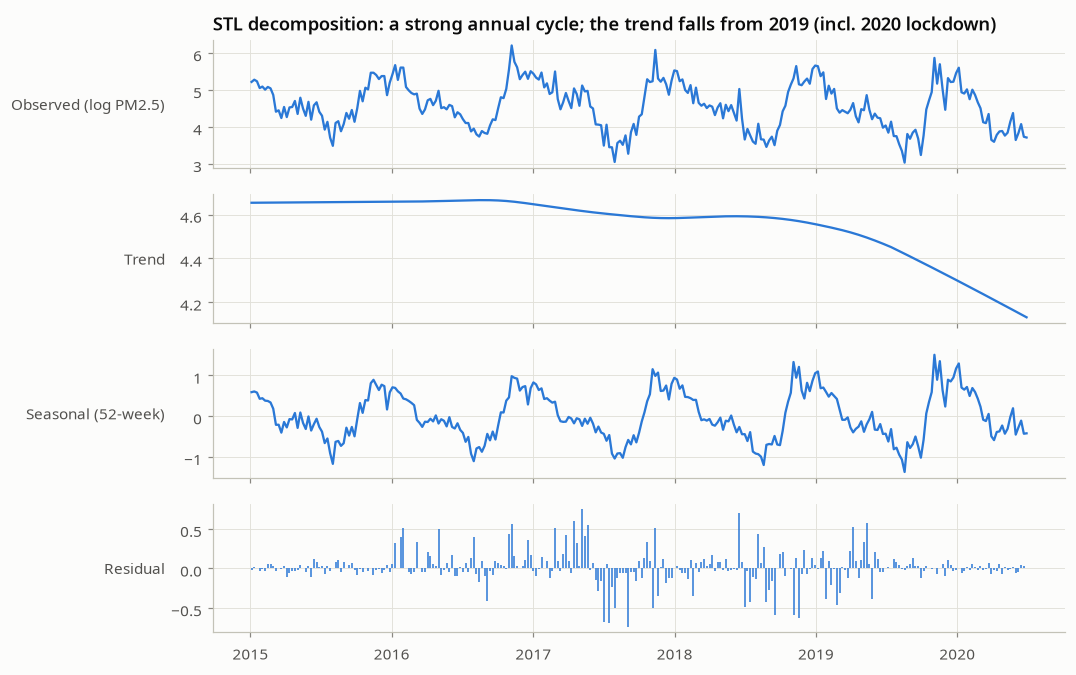

Seasonal strength F_S = 0.89 | Trend strength F_T = 0.34


In [6]:
stl = STL(weekly["log_pm25"], period=52, robust=True).fit()
fig, axes = plt.subplots(4, 1, figsize=(10, 7), sharex=True)
parts = [("Observed (log PM2.5)", stl.observed), ("Trend", stl.trend),
         ("Seasonal (52-week)", stl.seasonal), ("Residual", stl.resid)]
for ax, (name, series) in zip(axes, parts):
    if name == "Residual":
        ax.vlines(series.index, 0, series, color=BLUE, lw=1)
    else:
        ax.plot(series.index, series, color=BLUE)
    ax.set_ylabel(name, rotation=0, ha="right", va="center")
axes[0].set_title("STL decomposition: a strong annual cycle; the trend falls from 2019 (incl. 2020 lockdown)")
fig.align_ylabels(axes)
savefig(fig, "03_stl_decomposition")
plt.show()

var_resid = np.var(stl.resid)
key["seasonal_strength"] = round(float(max(0, 1 - var_resid / np.var(stl.seasonal + stl.resid))), 2)
key["trend_strength"] = round(float(max(0, 1 - var_resid / np.var(stl.trend + stl.resid))), 2)
print("Seasonal strength F_S =", key["seasonal_strength"], "| Trend strength F_T =", key["trend_strength"])

Seasonal strength $F_S = 1 - \mathrm{Var}(R)/\mathrm{Var}(S+R)$ is close to 1, so seasonality dominates.
This is why we use a **seasonal** ARIMA with s = 52.

## 4. How PM2.5 moves with pollutants and weather

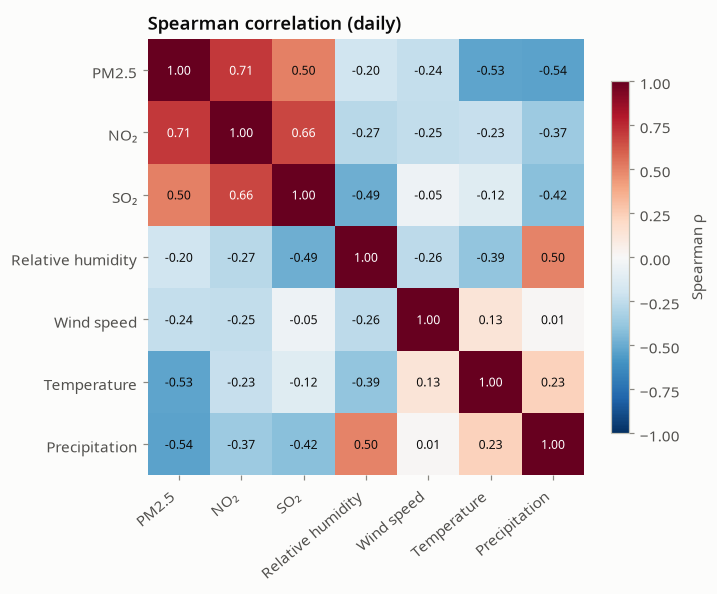

In [7]:
cols = ["pm25", "no2", "so2", "rh", "wind", "temp", "precip"]
corr = daily[cols].corr(method="spearman")
names = [LABELS[c].split(" (")[0] for c in cols]

fig, ax = plt.subplots(figsize=(6.4, 5.2))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), names, rotation=40, ha="right")
ax.set_yticks(range(len(cols)), names)
ax.grid(False)
for i in range(len(cols)):
    for j in range(len(cols)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.55 else INK)
for s in ax.spines.values():
    s.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman ρ")
ax.set_title("Spearman correlation (daily)")
savefig(fig, "04_correlation_heatmap")
plt.show()
key["spearman_pm25_wind"] = round(float(corr.loc["pm25", "wind"]), 2)
key["spearman_pm25_rh"] = round(float(corr.loc["pm25", "rh"]), 2)

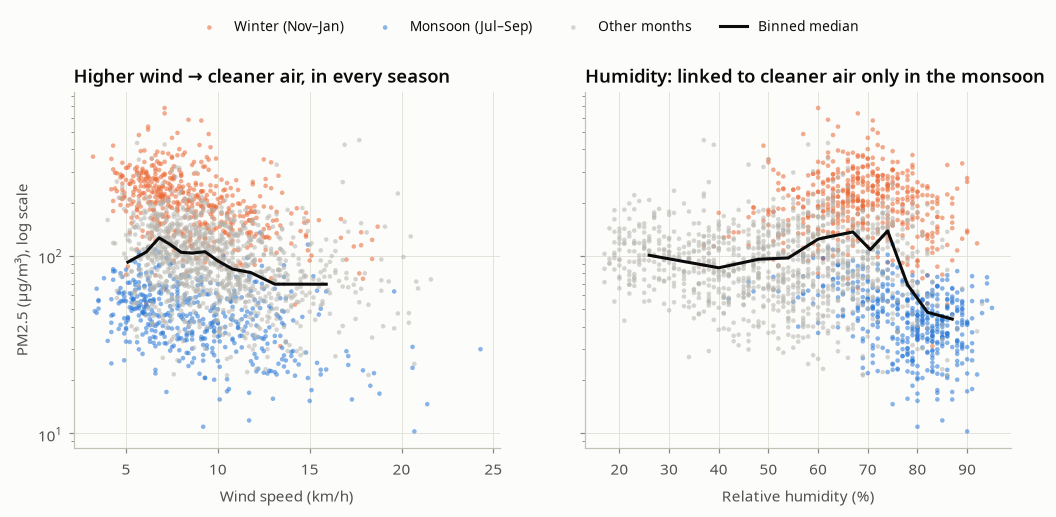

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, x in zip(axes, ["wind", "rh"]):
    for season, c in SEASON_COLORS.items():
        d = daily[daily["season"] == season]
        ax.scatter(d[x], d["pm25"], s=9, color=c, alpha=0.55, edgecolors="none", label=season)
    bins = pd.qcut(daily[x], 12)
    med = daily.groupby(bins, observed=True).agg(x=(x, "median"), y=("pm25", "median"))
    ax.plot(med["x"], med["y"], color=INK, lw=2, label="Binned median")
    ax.set_xlabel(LABELS[x])
    ax.set_yscale("log")
axes[0].set_ylabel(LABELS["pm25"] + ", log scale")
axes[0].set_title("Higher wind → cleaner air, in every season")
axes[1].set_title("Humidity: linked to cleaner air only in the monsoon")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncols=4, bbox_to_anchor=(0.5, 1.07))
savefig(fig, "05_pm25_vs_weather")
plt.show()

Pooled correlations mix the seasons together, so we check them **within each season**:

In [9]:
within = daily.groupby("season").apply(lambda g: pd.Series({
    "ρ(PM2.5, wind)": g["pm25"].corr(g["wind"], method="spearman"),
    "ρ(PM2.5, RH)": g["pm25"].corr(g["rh"], method="spearman"),
    "days": len(g),
})).round(2)
within.to_csv(RESULTS / "within_season_correlation.csv")
within

,"ρ(PM2.5, wind)","ρ(PM2.5, RH)",days
season,,,
Monsoon (Jul–Sep),-0.39,-0.37,461.0
Other months,-0.30,-0.02,1057.0
Winter (Nov–Jan),-0.47,-0.02,491.0


* **Wind** is negatively correlated with PM2.5 in *every* season (strongest in winter). More wind means more
  dilution.
* **Humidity** is negatively correlated only in the **monsoon** (rain washout). In winter it is ≈ 0.
* These are correlations, not causes. Notebook 03 tests whether weather *predicts* PM2.5 (Granger).

## 5. Autocorrelation

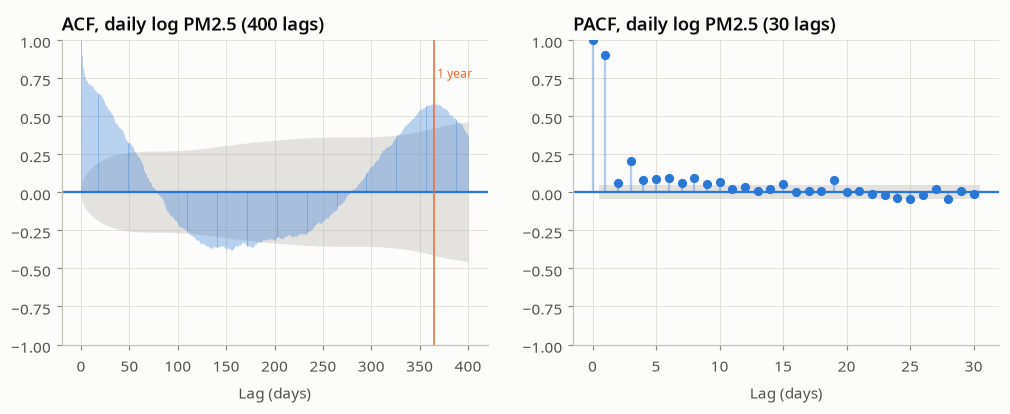

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
plot_acf(daily["log_pm25"].dropna(), lags=400, ax=axes[0], marker=None, color=BLUE,
         vlines_kwargs={"colors": BLUE, "lw": 0.6}, title="ACF, daily log PM2.5 (400 lags)")
plot_pacf(daily["log_pm25"].dropna(), lags=30, ax=axes[1], method="ywm", color=BLUE,
          vlines_kwargs={"colors": BLUE}, title="PACF, daily log PM2.5 (30 lags)")
for ax in axes:
    ax.set_xlabel("Lag (days)")
    for coll in ax.collections:
        coll.set_facecolor(NEUTRAL)
        coll.set_alpha(0.35)
axes[0].axvline(365, color=ORANGE, lw=1)
axes[0].text(368, 0.75, "1 year", color=ORANGE, fontsize=8)
savefig(fig, "06_acf_pacf")
plt.show()

The ACF decays slowly, dips negative at about 6 months and rises again near lag 365. This is the annual
cycle. The PACF cuts off after a few lags, so short-run dynamics look AR(1–2)-like.

## 6. Stationarity tests: ADF + KPSS
* **ADF**, H0: unit root (non-stationary). Small p means stationary.
* **KPSS**, H0: stationary. Small p means non-stationary.

The two tests have opposite null hypotheses, so running both gives a more reliable verdict.

In [11]:
log_w = weekly["log_pm25"]
tests = {
    "Daily PM2.5 (raw)": daily["pm25"],
    "Daily log PM2.5": daily["log_pm25"],
    "Daily Δ log PM2.5": daily["log_pm25"].diff(),
    "Daily wind speed": daily["wind"],
    "Daily Δ wind speed": daily["wind"].diff(),
    "Daily rel. humidity": daily["rh"],
    "Daily Δ rel. humidity": daily["rh"].diff(),
    "Weekly log PM2.5": log_w,
    "Weekly Δ log PM2.5 (d=1)": log_w.diff(),
    "Weekly Δ₅₂ log PM2.5 (D=1)": log_w.diff(52),
    "Weekly Δ Δ₅₂ log PM2.5 (d=1, D=1)": log_w.diff(52).diff(),
}
stationarity = stationarity_table(tests)
stationarity.to_csv(RESULTS / "stationarity.csv")
stationarity

/home/kushagrasingh/Music/time_anal_proj/notebooks/../src/tsa.py:12: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, adf_lags, *_ = adfuller(s, autolag="AIC")
/home/kushagrasingh/Music/time_anal_proj/notebooks/../src/tsa.py:12: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, adf_lags, *_ = adfuller(s, autolag="AIC")


/home/kushagrasingh/Music/time_anal_proj/notebooks/../src/tsa.py:12: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, adf_lags, *_ = adfuller(s, autolag="AIC")
/home/kushagrasingh/Music/time_anal_proj/notebooks/../src/tsa.py:12: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, adf_lags, *_ = adfuller(s, autolag="AIC")


/home/kushagrasingh/Music/time_anal_proj/notebooks/../src/tsa.py:12: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, adf_lags, *_ = adfuller(s, autolag="AIC")
/home/kushagrasingh/Music/time_anal_proj/notebooks/../src/tsa.py:12: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, adf_lags, *_ = adfuller(s, autolag="AIC")


/home/kushagrasingh/Music/time_anal_proj/notebooks/../src/tsa.py:12: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, adf_lags, *_ = adfuller(s, autolag="AIC")
/home/kushagrasingh/Music/time_anal_proj/notebooks/../src/tsa.py:12: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, adf_lags, *_ = adfuller(s, autolag="AIC")
/home/kushagrasingh/Music/

,n,adf_stat,adf_p,adf_lags,kpss_stat,kpss_p,verdict
series,,,,,,,
Daily PM2.5 (raw),2009,-3.980,0.0015,17,0.224,0.1000,Stationary
Daily log PM2.5,2009,-3.089,0.0274,18,0.366,0.0917,Stationary
Daily Δ log PM2.5,2008,-15.229,0.0000,17,0.031,0.1000,Stationary
Daily wind speed,2009,-13.142,0.0000,6,0.540,0.0326,"Mixed (ADF says stationary, KPSS rejects)"
Daily Δ wind speed,2008,-15.186,0.0000,26,0.141,0.1000,Stationary
Daily rel. humidity,2009,-4.521,0.0002,9,0.052,0.1000,Stationary
Daily Δ rel. humidity,2008,-20.681,0.0000,8,0.015,0.1000,Stationary
Weekly log PM2.5,287,-5.389,0.0000,9,0.158,0.1000,Stationary
Weekly Δ log PM2.5 (d=1),286,-9.743,0.0000,2,0.027,0.1000,Stationary


**Reading the table** (statsmodels caps the KPSS p-value at 0.1, so 0.1 means "≥ 0.1"):
* **No unit root in PM2.5.** Daily and weekly log PM2.5 *levels* pass both tests. The annual cycle is a
  repeating, mean-reverting pattern, not a random walk.
* **Wind (daily)** is borderline: ADF rejects a unit root but KPSS rejects stationarity at 5%.
  Its first difference is clearly stationary.
* **Weekly SARIMAX:** the seasonal difference Δ₅₂ alone is still borderline (KPSS p ≈ 0.02). Δ₅₂ followed by
  a first difference passes cleanly. Phase 4 will compare **D = 0 vs D = 1** (and d = 0/1) on held-out error
  and residual diagnostics, not only AIC. AIC isn't comparable across different amounts of differencing.
* **Stationary does not mean ready for Granger.** Wind, humidity and PM2.5 all follow the same annual
  calendar. Unless we remove that shared seasonal cycle first (notebook 03), Granger tests would pick up
  "the season" instead of a real lead-lag relationship.

In [12]:
(RESULTS / "key_numbers_eda.json").write_text(json.dumps(key, indent=2))
key

{'pct_days_poor_or_worse': 52.2,
 'winter_mean_pm25': 213.3,
 'monsoon_mean_pm25': 48.1,
 'winter_to_monsoon_ratio': 4.43,
 'nov_to_aug_median_ratio': 4.9,
 'seasonal_strength': 0.89,
 'trend_strength': 0.34,
 'spearman_pm25_wind': -0.24,
 'spearman_pm25_rh': -0.2}